# 09 — Etapa 2: ablaciones HAI22.04

**Objetivo:** cuantificar qué cambia al retirar las señales de entrada de P1, P2, P3 o P4 respecto a FULL, conservando las mismas 24 señales objetivo. Se analizan **DT, RF, ET y XGB** en **TEST2, TEST3 y TEST4**, sin entrenamiento ni ajuste de umbrales.

**Criterio:** la ablación mide la dependencia del desempeño respecto a la información retirada, **no** prueba causalidad ni identifica por sí sola nuevos regímenes. Persistencia se conserva únicamente como referencia externa de la Etapa 1; no tiene ablaciones.

**Convenciones:** `delta_rmse = RMSE_SIN - RMSE_FULL` (positivo = empeora); `delta_mae` igual; `delta_r2 = R²_SIN - R²_FULL` (negativo = empeora). Los porcentajes de cambio solo se calculan con denominador FULL no nulo.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(r"C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles")
OUT = ROOT / "analisis" / "etapa_2"
OUT.mkdir(parents=True, exist_ok=True)
METHODS = ["DT", "RF", "ET", "XGB"]
CONFIGS = ["FULL", "SIN_P1", "SIN_P2", "SIN_P3", "SIN_P4"]
TESTS = ["test2", "test3", "test4"]
BASE_COLS = ["modelo", "configuracion", "test", "componente", "variable"]
assert (ROOT / "metricas").is_dir(), f"No existe {ROOT / 'metricas'}"
print("Datos:", ROOT)
print("Salidas:", OUT)


Datos: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles
Salidas: C:\Users\hugoc\Local\PUCV\Doctorado\Cursos\Semestre-2-2026\Industria-Inteligente\archive\resultados_hai_arboles\analisis\etapa_2


## 1. RMSE y MAE por señal
Los CSV de métricas existentes son la fuente para RMSE/MAE. Se verifica la presencia de las 24 señales en cada configuración y TEST antes de comparar.

In [5]:
frames=[]
missing=[]
for model in METHODS:
    for cfg in CONFIGS:
        p=ROOT / "metricas" / f"prediccion_{model}_{cfg}.csv"
        if not p.exists():
            missing.append(str(p));continue
        d=pd.read_csv(p)
        expected={"archivo","variable","componente","rmse","mae"}
        if not expected.issubset(d.columns):
            raise ValueError(f"Columnas faltantes en {p}: {expected-set(d.columns)}")
        d["test"]=d["archivo"].astype(str).str.lower().str.extract(r"(test[234])", expand=False)
        d=d[d["test"].isin(TESTS)].copy()
        d["modelo"]=model;d["configuracion"]=cfg
        frames.append(d[BASE_COLS+["rmse","mae"]])
if missing:raise FileNotFoundError("Faltan métricas requeridas:\n"+"\n".join(missing))
metrics=pd.concat(frames,ignore_index=True)
if metrics.duplicated(BASE_COLS).any():
    raise ValueError("Existen métricas duplicadas por modelo/configuración/test/componente/señal")
expected_keys={(m,c,t) for m in METHODS for c in CONFIGS for t in TESTS}
found_keys=set(map(tuple,metrics[["modelo","configuracion","test"]].drop_duplicates().to_numpy()))
if found_keys!=expected_keys:raise ValueError(f"Combinaciones ausentes: {expected_keys-found_keys}")
counts=metrics.groupby(["modelo","configuracion","test"]).agg(senales=("variable","nunique"),filas=("variable","size"))
if not ((counts.senales==24)&(counts.filas==24)).all():
    raise ValueError("Una o varias combinaciones no contienen exactamente 24 señales únicas")
# La identidad de las señales debe mantenerse en todas las configuraciones
for (m,t),g in metrics.groupby(["modelo","test"]):
    base=set(g[g.configuracion=="FULL"]["variable"])
    for cfg in CONFIGS[1:]:
        other=set(g[g.configuracion==cfg]["variable"])
        if base!=other:raise ValueError(f"Señales incompatibles: {m} {t} {cfg}")
metrics.to_csv(OUT/"01_metricas_por_senal_ablaciones.csv",index=False)
print("RMSE/MAE:",len(metrics),"filas;",len(counts),"combinaciones")


RMSE/MAE: 1440 filas; 60 combinaciones


## 2. Calcular R² desde los GZIP originales
Se leen **únicamente** las columnas reales y predichas necesarias, un archivo y un bloque a la vez. No se descomprimen los archivos a disco. El cálculo acumula suma, suma de cuadrados y errores cuadrados para obtener el R² global de cada señal y TEST. Las señales constantes pueden tener R² indefinido.


In [6]:
def prediction_file(model,cfg,test):
    base=ROOT/"predicciones"/f"{model}_{cfg}_{test}.csv.gz"
    if base.exists():return base
    alternative=base.with_suffix("")
    if alternative.exists():return alternative
    raise FileNotFoundError(f"No se encontró predicción: {base}")

def compute_r2_file(p, variables, chunk_size=15000):
    # Los archivos originales pueden ser GZIP aun si Windows oculta la extensión.
    compression="gzip" if p.suffix.lower()==".gz" else "infer"
    if p.suffix.lower()!=".gz":
        with p.open("rb") as f:
            if f.read(2)==bytes([31,139]):compression="gzip"
    cols=pd.read_csv(p,compression=compression,nrows=0).columns.tolist()
    needed=[q for v in variables for q in ("real__"+v,"pred__"+v)]
    missing=set(needed)-set(cols)
    if missing:raise ValueError(f"Faltan columnas en {p.name}: {sorted(missing)}")
    totals={v:[0,0.,0.,0.] for v in variables} # N, sum_y, sum_y2, SSE
    for chunk in pd.read_csv(p,compression=compression,usecols=needed,chunksize=chunk_size):
        for v in variables:
            y=pd.to_numeric(chunk["real__"+v],errors="coerce").to_numpy(dtype=float)
            yp=pd.to_numeric(chunk["pred__"+v],errors="coerce").to_numpy(dtype=float)
            mask=np.isfinite(y)&np.isfinite(yp)
            y=y[mask];yp=yp[mask]
            t=totals[v];t[0]+=len(y);t[1]+=float(y.sum());t[2]+=float(np.square(y).sum());t[3]+=float(np.square(y-yp).sum())
    rows=[]
    for v,(count,sy,sy2,sse) in totals.items():
        sst=sy2-sy*sy/count if count else np.nan
        if count==0: state="SIN_OBSERVACIONES";r2=np.nan
        elif sst<=max(1e-10,abs(sy2)*1e-12):state="SIN_VARIANZA";r2=np.nan
        else:state="OK";r2=1-sse/sst
        rows.append({"variable":v,"r2":r2,"n_r2":count,"estado_r2":state,"sse":sse,"sst":sst})
    return rows

all_r2=[]
for i,(model,cfg,test) in enumerate(sorted(expected_keys),1):
    sub=metrics[(metrics.modelo==model)&(metrics.configuracion==cfg)&(metrics.test==test)]
    p=prediction_file(model,cfg,test)
    for row in compute_r2_file(p,sub.variable.tolist()):
        all_r2.append({"modelo":model,"configuracion":cfg,"test":test,**row})
    print(f"{i:02d}/60 {model} {cfg} {test}")
r2=pd.DataFrame(all_r2)
metrics=metrics.merge(r2[BASE_COLS[:3]+["variable","r2","n_r2","estado_r2"]],on=["modelo","configuracion","test","variable"],validate="one_to_one")
metrics.to_csv(OUT/"01_metricas_por_senal_ablaciones.csv",index=False)
r2.to_csv(OUT/"02_r2_ablaciones.csv",index=False)
print("R² OK:",(r2.estado_r2=="OK").sum(),"de",len(r2))


01/60 DT FULL test2
02/60 DT FULL test3
03/60 DT FULL test4
04/60 DT SIN_P1 test2
05/60 DT SIN_P1 test3
06/60 DT SIN_P1 test4
07/60 DT SIN_P2 test2
08/60 DT SIN_P2 test3
09/60 DT SIN_P2 test4
10/60 DT SIN_P3 test2
11/60 DT SIN_P3 test3
12/60 DT SIN_P3 test4
13/60 DT SIN_P4 test2
14/60 DT SIN_P4 test3
15/60 DT SIN_P4 test4
16/60 ET FULL test2
17/60 ET FULL test3
18/60 ET FULL test4
19/60 ET SIN_P1 test2
20/60 ET SIN_P1 test3
21/60 ET SIN_P1 test4
22/60 ET SIN_P2 test2
23/60 ET SIN_P2 test3
24/60 ET SIN_P2 test4
25/60 ET SIN_P3 test2
26/60 ET SIN_P3 test3
27/60 ET SIN_P3 test4
28/60 ET SIN_P4 test2
29/60 ET SIN_P4 test3
30/60 ET SIN_P4 test4
31/60 RF FULL test2
32/60 RF FULL test3
33/60 RF FULL test4
34/60 RF SIN_P1 test2
35/60 RF SIN_P1 test3
36/60 RF SIN_P1 test4
37/60 RF SIN_P2 test2
38/60 RF SIN_P2 test3
39/60 RF SIN_P2 test4
40/60 RF SIN_P3 test2
41/60 RF SIN_P3 test3
42/60 RF SIN_P3 test4
43/60 RF SIN_P4 test2
44/60 RF SIN_P4 test3
45/60 RF SIN_P4 test4
46/60 XGB FULL test2
47/60 X

## 3. Comparación pareada FULL vs. SIN_Pn
Diferencias absolutas y relativas **por la misma señal y TEST**. No se promedian RMSE o MAE de señales con unidades distintas. Se informa por separado la dirección de la mejora para cada métrica.

In [7]:
full=metrics[metrics.configuracion=="FULL"].drop(columns="configuracion")
abl=metrics[metrics.configuracion!="FULL"]
paired=abl.merge(full,on=["modelo","test","componente","variable"],suffixes=("_sin","_full"),validate="many_to_one")
assert len(paired)==4*4*3*24, "Faltan comparaciones pareadas"
for m in ["rmse","mae","r2"]:
    paired["delta_"+m]=paired[m+"_sin"]-paired[m+"_full"]
for m in ["rmse","mae"]:
    d=paired[m+"_full"].to_numpy(dtype=float)
    paired["cambio_pct_"+m]=np.where(d!=0,100*paired["delta_"+m]/d,np.nan)
paired["efecto_rmse"] = np.select([paired.delta_rmse>0,paired.delta_rmse<0],["EMPEORA","MEJORA"],default="IGUAL")
paired["efecto_r2"] = np.select([paired.delta_r2<0,paired.delta_r2>0],["EMPEORA","MEJORA"],default="IGUAL")
paired.to_csv(OUT/"03_comparacion_pareada_ablaciones.csv",index=False)
summary=(paired.groupby(["modelo","configuracion","test"],as_index=False)
         .agg(senales=("variable","size"),rmse_empeora=("delta_rmse",lambda x:int((x>0).sum())),
              rmse_mejora=("delta_rmse",lambda x:int((x<0).sum())),
              mae_empeora=("delta_mae",lambda x:int((x>0).sum())),
              r2_empeora=("delta_r2",lambda x:int((x<0).sum())),
              r2_mejora=("delta_r2",lambda x:int((x>0).sum())),
              mediana_delta_r2=("delta_r2","median"),
              mediana_cambio_pct_rmse=("cambio_pct_rmse","median"),
              mediana_cambio_pct_mae=("cambio_pct_mae","median")))
summary.to_csv(OUT/"04_resumen_ablaciones_por_test.csv",index=False)
by_component=(paired.groupby(["modelo","configuracion","componente"],as_index=False)
              .agg(senales_test=("variable","size"),mediana_delta_r2=("delta_r2","median"),
                   rmse_empeora=("delta_rmse",lambda x:int((x>0).sum())),
                   rmse_mejora=("delta_rmse",lambda x:int((x<0).sum())),
                   mediana_cambio_pct_rmse=("cambio_pct_rmse","median")))
by_component.to_csv(OUT/"05_resumen_ablaciones_por_componente.csv",index=False)
print(summary.head(8).to_string(index=False))


modelo configuracion  test  senales  rmse_empeora  rmse_mejora  mae_empeora  r2_empeora  r2_mejora  mediana_delta_r2  mediana_cambio_pct_rmse  mediana_cambio_pct_mae
    DT        SIN_P1 test2       24            12           12           12          12         12         -0.002103                -0.040340                0.101398
    DT        SIN_P1 test3       24            11           13           11          11         13          0.019808                -1.172788               -0.893441
    DT        SIN_P1 test4       24            14           10           13          14         10         -0.035744                 1.615147                1.684674
    DT        SIN_P2 test2       24             8           16            8           8         16          0.036362                -1.361464               -3.871817
    DT        SIN_P2 test3       24            13           11           12          13         11         -0.004992                 0.366569               -0.176796
    

## 4. Desviaciones señaladas y correspondencia con episodios
Se utilizan exclusivamente los **resúmenes de detección ya producidos**, sin recalcular puntuaciones ni umbrales. El número de intervalos etiquetados coincidentes es un contraste externo: no equivale a número de anomalías operacionales reales.

In [8]:
det=[];eps=[]
for model in METHODS:
    for cfg in CONFIGS:
        fp=ROOT/"metricas"/f"deteccion_{model}_{cfg}.csv"
        ep=ROOT/"metricas"/f"episodios_{model}_{cfg}.csv"
        if not fp.exists() or not ep.exists():
            raise FileNotFoundError(f"Falta resumen: {fp if not fp.exists() else ep}")
        d=pd.read_csv(fp)
        e=pd.read_csv(ep)
        req={"archivo","n","n_alerta","fraccion_alerta","episodios_visibles","episodios_detectados"}
        if not req.issubset(d.columns):raise ValueError(f"Columnas faltantes {fp.name}: {req-set(d.columns)}")
        if not {"archivo","detectado"}.issubset(e.columns):raise ValueError(f"Columnas faltantes {ep.name}")
        d["test"]=d.archivo.astype(str).str.lower().str.extract(r"(test[234])",expand=False)
        e["test"]=e.archivo.astype(str).str.lower().str.extract(r"(test[234])",expand=False)
        d=d[d.test.isin(TESTS)].copy();e=e[e.test.isin(TESTS)].copy()
        if d.test.duplicated().any() or set(d.test)!=set(TESTS):raise ValueError(f"TEST inesperados en {fp.name}")
        for _,row in d.iterrows():
            subset=e[e.test==row.test]
            detected=pd.to_numeric(subset.detectado,errors="coerce")
            if detected.isna().any():raise ValueError(f"Etiqueta de episodio desconocida en {ep.name}")
            total=len(subset); hits=int((detected!=0).sum())
            if total!=int(row.episodios_visibles) or hits!=int(row.episodios_detectados):
                raise ValueError(f"No coincide resumen de episodios para {model} {cfg} {row.test}")
            det.append({"modelo":model,"configuracion":cfg,"test":row.test,
                        "registros":int(row.n),"registros_senalados":int(row.n_alerta),
                        "proporcion_senalados_pct":100*float(row.n_alerta)/int(row.n),
                        "episodios_etiquetados":total,"episodios_coincidentes":hits,
                        "correspondencia_pct":100*hits/total if total else np.nan})
det=pd.DataFrame(det)
full_det=det[det.configuracion=="FULL"].drop(columns="configuracion")
detpaired=det[det.configuracion!="FULL"].merge(full_det,on=["modelo","test"],suffixes=("_sin","_full"),validate="many_to_one")
for m in ["proporcion_senalados_pct","correspondencia_pct"]:
    detpaired["delta_"+m]=detpaired[m+"_sin"]-detpaired[m+"_full"]
for m in ["registros","episodios_etiquetados"]:
    if not (detpaired[m+"_sin"]==detpaired[m+"_full"]).all():
        raise ValueError(f"No coincide denominador {m} entre FULL y SIN_Pn")
det.to_csv(OUT/"06_desviaciones_y_episodios.csv",index=False)
detpaired.to_csv(OUT/"07_comparacion_deteccion_ablaciones.csv",index=False)
print(detpaired[["modelo","configuracion","test","delta_proporcion_senalados_pct","delta_correspondencia_pct"]].head(8).to_string(index=False))


modelo configuracion  test  delta_proporcion_senalados_pct  delta_correspondencia_pct
    DT        SIN_P1 test2                       -0.047119                  11.764706
    DT        SIN_P1 test3                        0.389610                   0.000000
    DT        SIN_P1 test4                        2.100795                  -8.333333
    DT        SIN_P2 test2                        0.637912                  -5.882353
    DT        SIN_P2 test3                        1.321148                  10.000000
    DT        SIN_P2 test4                        0.624373                  -8.333333
    DT        SIN_P3 test2                        0.865048                   0.000000
    DT        SIN_P3 test3                        0.970018                   0.000000


## 5. Figuras científicas
Dos gráficos complementarios: **(a)** efecto de excluir cada componente sobre el R² por método, y **(b)** cambios en porcentaje de registros señalados, ambos frente a FULL. Valores positivos de `ΔR²` representan mejora tras excluir información. Los gráficos no establecen causalidad.

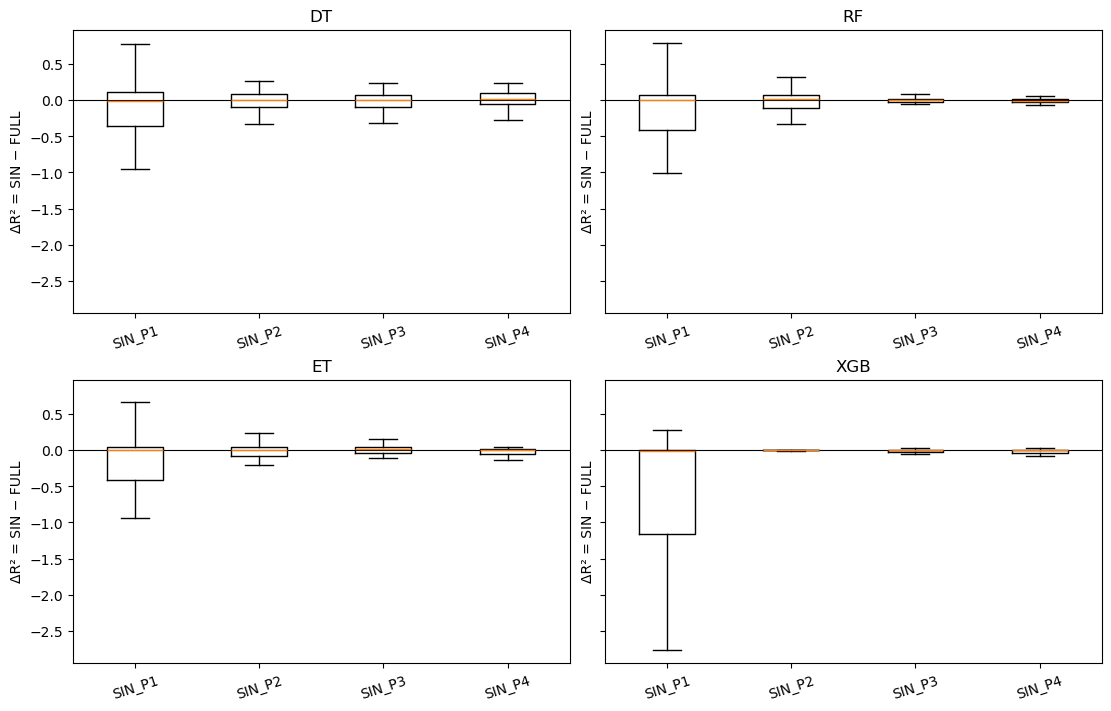

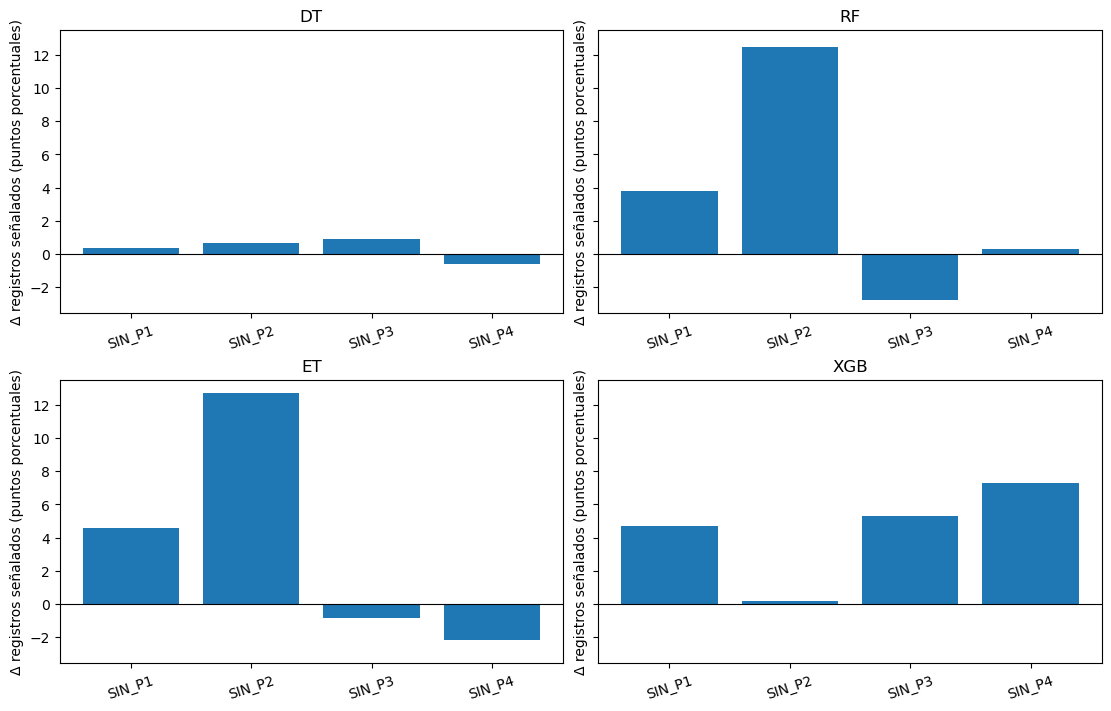

In [9]:
fig,axes=plt.subplots(2,2,figsize=(11,7),sharey=True,constrained_layout=True)
for ax,model in zip(axes.flat,METHODS):
    f=paired[paired.modelo==model]
    data=[f[f.configuracion==cfg]["delta_r2"].dropna().to_numpy() for cfg in CONFIGS[1:]]
    ax.boxplot(data,tick_labels=CONFIGS[1:],showfliers=False)
    ax.axhline(0,color="black",linewidth=0.8)
    ax.set_title(model);ax.tick_params(axis="x",rotation=18)
    ax.set_ylabel("ΔR² = SIN − FULL")
fig.savefig(OUT/"figura_ablacion_delta_r2.pdf",bbox_inches="tight")
fig.savefig(OUT/"figura_ablacion_delta_r2.png",dpi=300,bbox_inches="tight")
plt.show()

fig,axes=plt.subplots(2,2,figsize=(11,7),sharey=True,constrained_layout=True)
for ax,model in zip(axes.flat,METHODS):
    f=detpaired[detpaired.modelo==model]
    dat=f.groupby("configuracion")["delta_proporcion_senalados_pct"].median().reindex(CONFIGS[1:])
    ax.bar(dat.index,dat.values)
    ax.axhline(0,color="black",linewidth=0.8)
    ax.set_title(model);ax.tick_params(axis="x",rotation=18)
    ax.set_ylabel("Δ registros señalados (puntos porcentuales)")
fig.savefig(OUT/"figura_ablacion_delta_registros_senalados.pdf",bbox_inches="tight")
fig.savefig(OUT/"figura_ablacion_delta_registros_senalados.png",dpi=300,bbox_inches="tight")
plt.show()


## 6. Comprobación final y resumen para el artículo
El archivo de resumen registra cobertura y el número de filas generadas. **No se redactan conclusiones automáticamente.** Comparar cambios en métricas de predicción y señalamiento antes de interpretar la contribución de P1–P4.

In [10]:
required={
"01_metricas_por_senal_ablaciones.csv":4*5*3*24,
"02_r2_ablaciones.csv":4*5*3*24,
"03_comparacion_pareada_ablaciones.csv":4*4*3*24,
"04_resumen_ablaciones_por_test.csv":4*4*3,
"05_resumen_ablaciones_por_componente.csv":4*4*4,
"06_desviaciones_y_episodios.csv":4*5*3,
"07_comparacion_deteccion_ablaciones.csv":4*4*3,
}
checks=[]
for fname,expected in required.items():
    p=OUT/fname
    ok=p.exists()
    count=len(pd.read_csv(p)) if ok else -1
    checks.append({"archivo":fname,"filas":count,"esperadas":expected,"ok":ok and count==expected})
check=pd.DataFrame(checks)
check.to_csv(OUT/"08_cobertura_etapa2.csv",index=False)
print(check.to_string(index=False))
for f in ("figura_ablacion_delta_r2.pdf","figura_ablacion_delta_registros_senalados.pdf"):
    assert (OUT/f).exists(),f"No se generó {f}"
assert check.ok.all(),"Cobertura incompleta: revisar tabla de salida"
print("Etapa 2: artefactos generados correctamente. Compartir CSV 03, 04, 05, 07 y 08.")


                                 archivo  filas  esperadas   ok
    01_metricas_por_senal_ablaciones.csv   1440       1440 True
                    02_r2_ablaciones.csv   1440       1440 True
   03_comparacion_pareada_ablaciones.csv   1152       1152 True
      04_resumen_ablaciones_por_test.csv     48         48 True
05_resumen_ablaciones_por_componente.csv     64         64 True
         06_desviaciones_y_episodios.csv     60         60 True
 07_comparacion_deteccion_ablaciones.csv     48         48 True
Etapa 2: artefactos generados correctamente. Compartir CSV 03, 04, 05, 07 y 08.
